# Estimación de la resistencia del concreto
## Proyecto final de Machine Learning

**Pregunta:** ¿qué resistencia a compresión (MPa) podemos estimar a partir de los ingredientes de una mezcla y su edad?

**Usuario:** personal de un laboratorio de materiales que necesita una estimación preliminar para comparar mezclas. La predicción no reemplaza un ensayo ni certifica una estructura.

**Paradigma:** aprendizaje supervisado, regresión. Tenemos ejemplos con una resistencia real medida en laboratorio y queremos predecir un número.

**Fuente:** Yeh, I. (1998), *Concrete Compressive Strength*, UCI Machine Learning Repository. https://doi.org/10.24432/C5PK67. Se conserva el Excel y su README original. Licencia publicada por UCI: CC BY 4.0.

**Cómo ejecutar en Colab:** ejecuta las celdas en orden. La carga busca el Excel local, luego el repositorio de este proyecto y finalmente solicita subir `Concrete_Data.xls`. Los resultados guardados permiten revisar el trabajo sin volver a entrenar.

In [1]:
# Instalar únicamente si faltan librerías. En Colab normalmente solo faltará xlrd.
import importlib.util, subprocess, sys
for modulo, paquete in [('numpy','numpy'), ('pandas','pandas'), ('sklearn','scikit-learn'),
                         ('matplotlib','matplotlib'), ('xlrd','xlrd'), ('joblib','joblib')]:
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', paquete])

In [2]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
OUT = Path('results'); OUT.mkdir(exist_ok=True)
Path('models').mkdir(exist_ok=True)
Path('docs').mkdir(exist_ok=True)
print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.9.1


## 1. Datos y significado de las columnas
Las primeras siete variables son cantidades por metro cúbico de concreto (kg/m³). La edad se mide en días y la resistencia en MPa: un MPa equivale a un newton por milímetro cuadrado.

| Variable | Significado |
|---|---|
| cemento | Material aglutinante principal |
| escoria | Adición mineral procedente de alto horno |
| ceniza | Ceniza volante, otra adición mineral |
| agua | Cantidad de agua de la mezcla |
| superplastificante | Aditivo que facilita trabajar la mezcla |
| agregado_grueso | Partículas gruesas, como grava |
| agregado_fino | Partículas finas, como arena |
| edad | Días transcurridos hasta medir la resistencia |
| resistencia | Resistencia a compresión medida; es la respuesta, nunca una entrada |

In [3]:
ruta = Path('data/Concrete_Data.xls')
if not ruta.exists():
    ruta = Path('Concrete_Data.xls')
if not ruta.exists():
    from urllib.request import urlretrieve
    try:
        urlretrieve('https://raw.githubusercontent.com/cristiancabezas13/ProyectoFinal/main/data/Concrete_Data.xls', ruta)
    except Exception:
        from google.colab import files
        print('Sube el archivo Concrete_Data.xls original.')
        files.upload()

columnas = ['cemento','escoria','ceniza','agua','superplastificante',
            'agregado_grueso','agregado_fino','edad','resistencia']
original = pd.read_excel(ruta)
assert original.shape[1] == 9, 'El archivo debe tener las nueve columnas originales.'
datos = original.copy()
datos.columns = columnas
print('Filas y columnas originales:', datos.shape)
print('SHA256 del Excel:', hashlib.sha256(ruta.read_bytes()).hexdigest())
display(datos.head())

Filas y columnas originales: (1030, 9)
SHA256 del Excel: 710076c66b9ca3f8050e7942f3dcbdbe04013534daeb0077ffd3079a52d8e0c4


,cemento,escoria,ceniza,agua,superplastificante,agregado_grueso,agregado_fino,edad,resistencia
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


## 2. Calidad y preprocesamiento
Revisamos tipos, faltantes, duplicados y valores físicamente imposibles. Quitamos copias exactamente iguales de las nueve columnas para no darles peso extra. Si dos mediciones comparten entradas pero tienen respuestas distintas, las conservamos como variación experimental y las mantenemos en el mismo grupo.

Los ceros en algunas adiciones son válidos: indican que la mezcla no usa ese componente. Los valores extremos plausibles se conservarán. No creamos categorías artificiales ni escalamos: los árboles separan mediante umbrales y no dependen de distancias entre variables.

In [4]:
calidad = pd.DataFrame({'tipo': datos.dtypes.astype(str), 'faltantes': datos.isna().sum()})
display(calidad)
duplicados = int(datos.duplicated().sum())
print('Copias exactas eliminadas:', duplicados)
assert datos.isna().sum().sum() == 0, 'Revisar faltantes antes de continuar.'
assert all(pd.api.types.is_numeric_dtype(datos[c]) for c in columnas)
assert np.isfinite(datos.to_numpy()).all()
assert (datos.iloc[:, :7] >= 0).all().all()
assert (datos[['cemento','agua','edad','resistencia']] > 0).all().all()
datos = datos.drop_duplicates().reset_index(drop=True)
print('Filas conservadas:', len(datos))

,tipo,faltantes
cemento,float64,0
escoria,float64,0
ceniza,float64,0
agua,float64,0
superplastificante,float64,0
agregado_grueso,float64,0
agregado_fino,float64,0
edad,int64,0
resistencia,float64,0


Copias exactas eliminadas: 25
Filas conservadas: 1005


## 3. Separar antes de explorar y seleccionar
Una misma receta puede tener mediciones a diferentes edades. Una división aleatoria por filas podría poner esa receta en entrenamiento y prueba, facilitando la evaluación.

**Solución:** cada combinación exacta de los siete ingredientes es un grupo. Reservamos el 20 % de los grupos para prueba; el porcentaje de filas puede diferir del 20 %. El EDA y la búsqueda de hiperparámetros usan solo entrenamiento. Dentro del entrenamiento, la validación cruzada también separa por receta.

Esta evaluación aproxima el uso en recetas no vistas del mismo origen. No demuestra desempeño en cualquier laboratorio. No tenemos identificadores de lote y recetas casi iguales podrían permanecer en grupos diferentes; es una limitación.

In [5]:
features = columnas[:-1]
grupos = datos.groupby(columnas[:7], sort=True).ngroup()
X, y = datos[features], datos['resistencia']
split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
idx_train, idx_test = next(split.split(X, y, grupos))
X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
g_train, g_test = grupos.iloc[idx_train], grupos.iloc[idx_test]
assert set(g_train).isdisjoint(set(g_test))
train = datos.iloc[idx_train].copy()
print(f'Entrenamiento: {len(X_train)} filas, {g_train.nunique()} recetas')
print(f'Prueba reservada: {len(X_test)} filas, {g_test.nunique()} recetas')
print('Recetas compartidas: 0')
pd.DataFrame({'fila_limpia': datos.index, 'grupo': grupos,
              'particion': np.where(datos.index.isin(idx_train), 'train', 'test')}).to_csv(OUT/'particiones.csv', index=False)

Entrenamiento: 810 filas, 342 recetas
Prueba reservada: 195 filas, 86 recetas
Recetas compartidas: 0


## 4. EDA sobre entrenamiento
### 4.1. Rangos, distribución y valores extremos
Revisamos todas las variables. La regla de 1,5 veces el rango intercuartílico identifica observaciones para revisar, no errores que deban borrarse automáticamente.

,cemento,escoria,ceniza,agua,superplastificante,agregado_grueso,agregado_fino,edad,resistencia
count,810.00,810.00,810.00,810.00,810.00,810.00,810.00,810.00,810.00
mean,280.32,75.59,51.55,182.39,5.68,977.04,768.83,45.75,35.30
std,102.39,88.63,64.28,21.00,5.83,76.60,79.73,64.09,16.32
min,108.30,0.00,0.00,121.75,0.00,801.00,594.00,1.00,2.33
25%,194.68,0.00,0.00,168.08,0.00,932.00,719.78,7.00,23.52
50%,276.20,22.00,0.00,185.70,5.72,971.40,777.80,28.00,33.78
75%,339.15,145.00,113.00,192.00,9.90,1042.85,816.80,56.00,45.25
max,540.00,359.40,200.00,246.90,32.20,1145.00,992.60,365.00,81.75


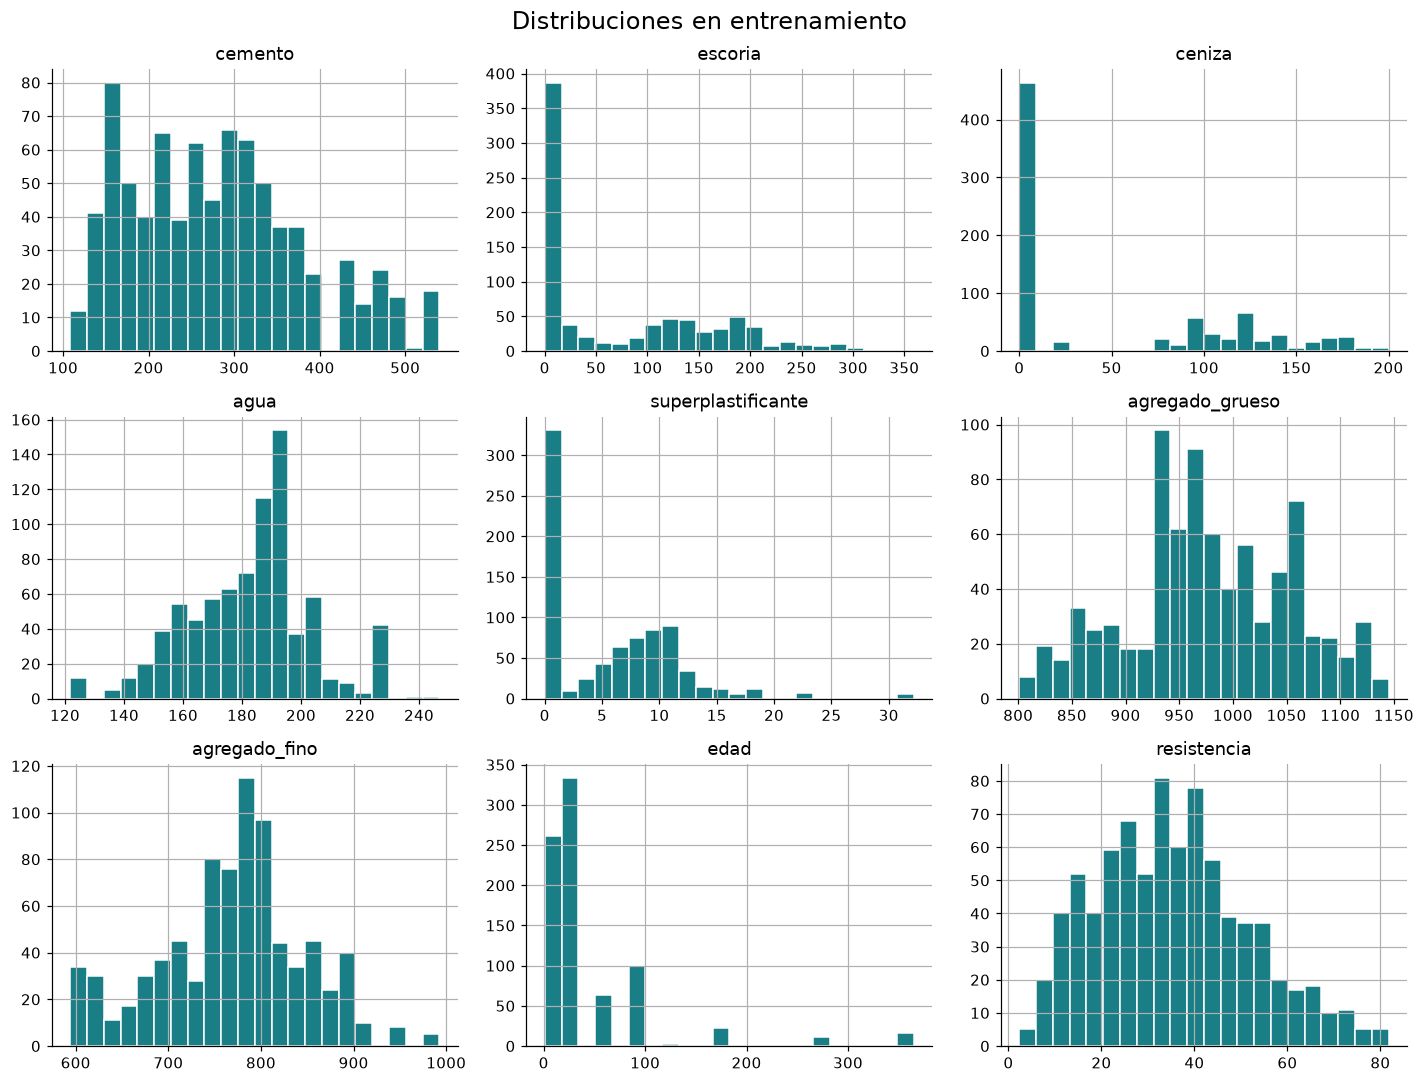

,posibles_atipicos_IQR,ceros
cemento,0,0
escoria,0,374
ceniza,0,464
agua,56,0
superplastificante,5,331
agregado_grueso,0,0
agregado_fino,5,0
edad,49,0
resistencia,5,0


Mediana de resistencia: 33.78 MPa
Edad más frecuente: [28]


In [6]:
display(train.describe().round(2))
train.hist(bins=22, figsize=(13, 10), color='#197e86', edgecolor='white')
plt.suptitle('Distribuciones en entrenamiento', fontsize=16)
plt.tight_layout(); plt.savefig(OUT/'01_distribuciones.png', bbox_inches='tight'); plt.show()
q1, q3 = train.quantile(.25), train.quantile(.75)
iqr = q3-q1
atipicos = ((train < q1-1.5*iqr) | (train > q3+1.5*iqr)).sum()
display(pd.DataFrame({'posibles_atipicos_IQR':atipicos, 'ceros':(train==0).sum()}))
print('Mediana de resistencia:', round(y_train.median(),2), 'MPa')
print('Edad más frecuente:', train.edad.mode().tolist())

**Decisión:** conservar edades altas y cantidades extremas que estén dentro de la documentación y no violen las comprobaciones físicas. No recortar la resistencia: eso alteraría la respuesta que intentamos aprender. La presencia de ceros válidos impide tratarlos como faltantes.

### 4.2. Relaciones con la resistencia
La correlación mide asociación lineal, no causalidad. Una correlación pequeña no descarta una relación útil no lineal.

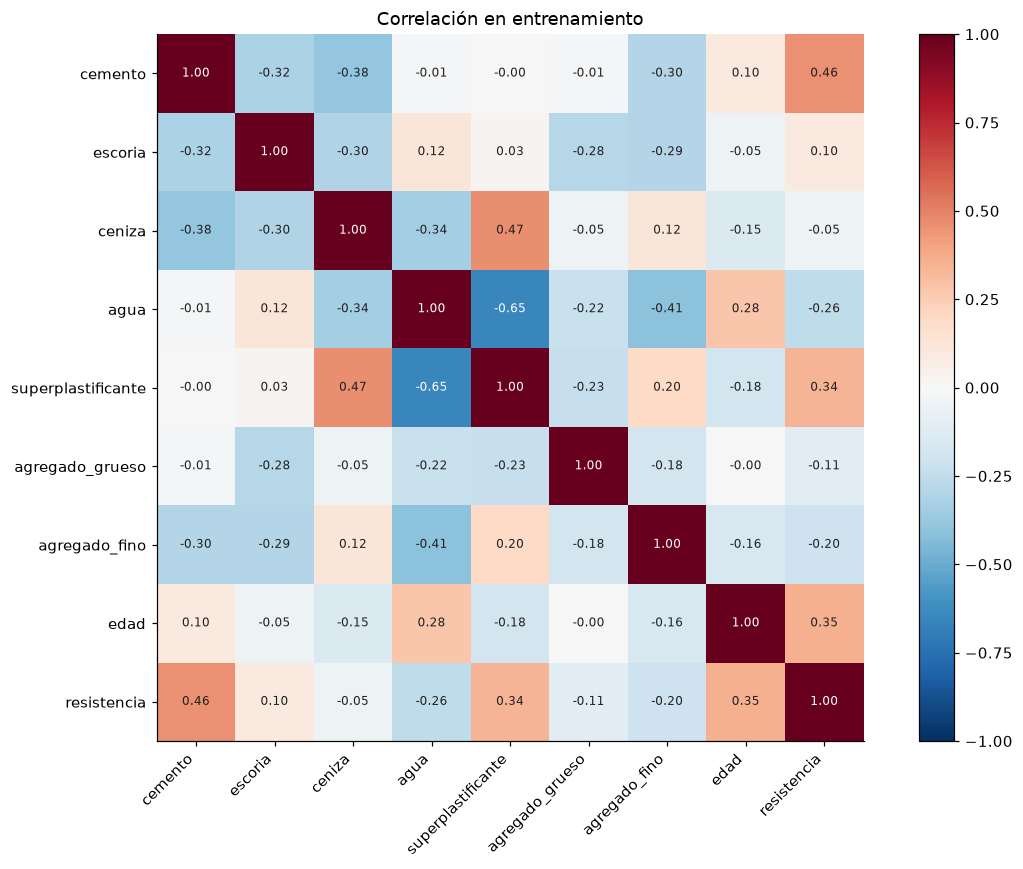

agua                 -0.258
agregado_fino        -0.203
agregado_grueso      -0.113
ceniza               -0.049
escoria               0.099
superplastificante    0.342
edad                  0.354
cemento               0.458
Name: resistencia, dtype: float64

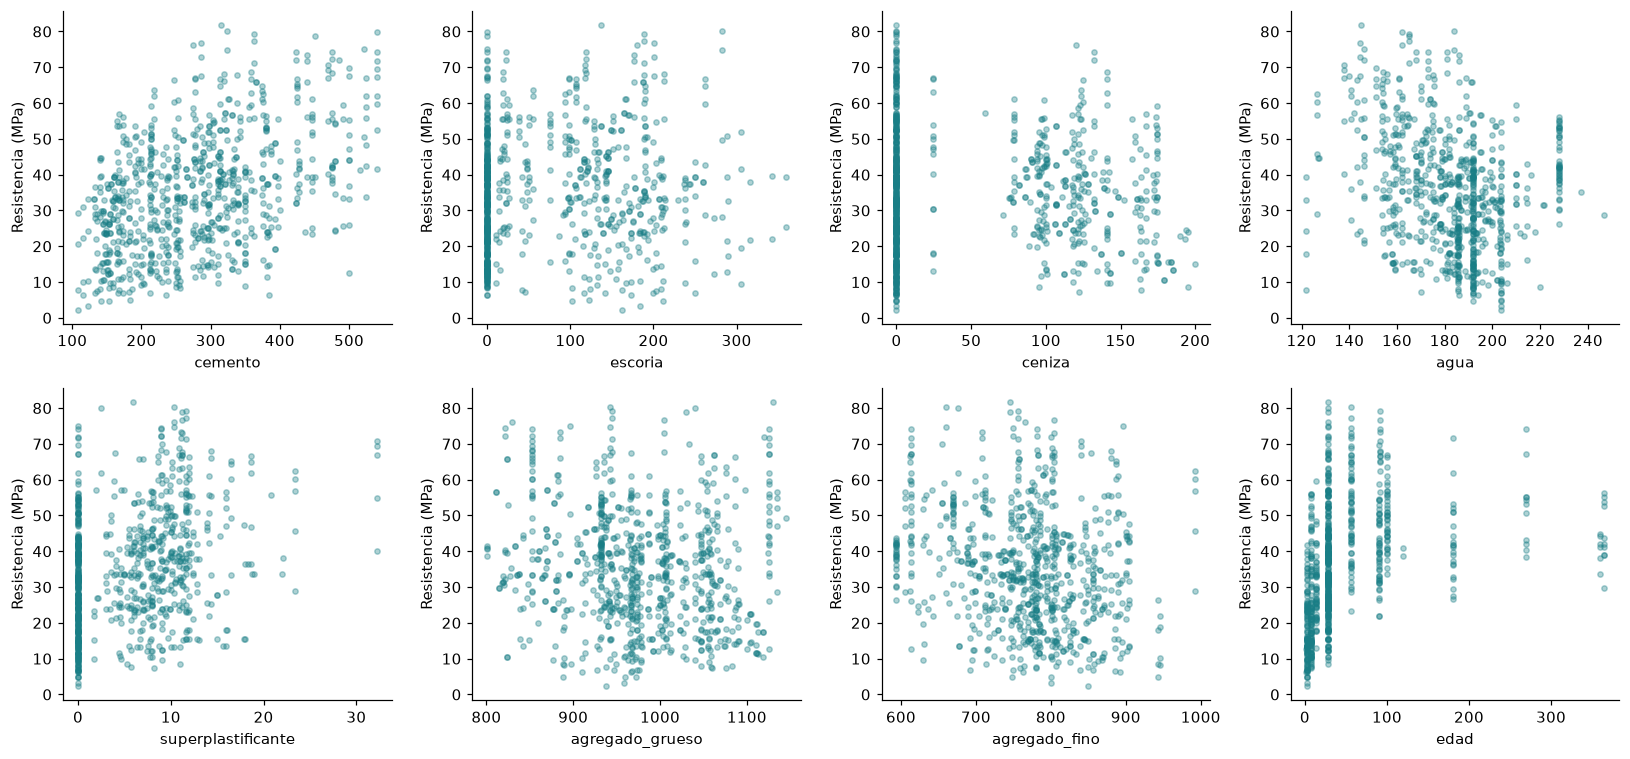

In [7]:
corr = train.corr()
fig, ax = plt.subplots(figsize=(11,8))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(9), columnas, rotation=45, ha='right')
ax.set_yticks(range(9), columnas)
for i in range(9):
    for j in range(9):
        ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8,
                color='white' if abs(corr.iloc[i,j])>.6 else '#202020')
fig.colorbar(im, ax=ax); ax.set_title('Correlación en entrenamiento')
plt.tight_layout(); plt.savefig(OUT/'02_correlaciones.png', bbox_inches='tight'); plt.show()
display(corr['resistencia'].drop('resistencia').sort_values().round(3))
fig, axes = plt.subplots(2, 4, figsize=(15,7))
for c, ax in zip(features, axes.flat):
    ax.scatter(train[c], y_train, s=12, alpha=.35, color='#197e86')
    ax.set(xlabel=c, ylabel='Resistencia (MPa)')
plt.tight_layout(); plt.savefig(OUT/'03_relaciones.png', bbox_inches='tight'); plt.show()

### 4.3. Edad y proporción agua/cemento
Comparamos rangos de edad y exploramos la proporción agua/cemento. Esta razón es solo un análisis exploratorio: no representa todos los materiales cementantes y no se añade al modelo para mantener ocho entradas originales.

,count,mean,median
rango_edad,,,
1-7 días,212,21.29,18.06
8-28 días,383,35.86,33.69
29-90 días,112,46.86,45.86
91-365 días,103,49.52,47.74


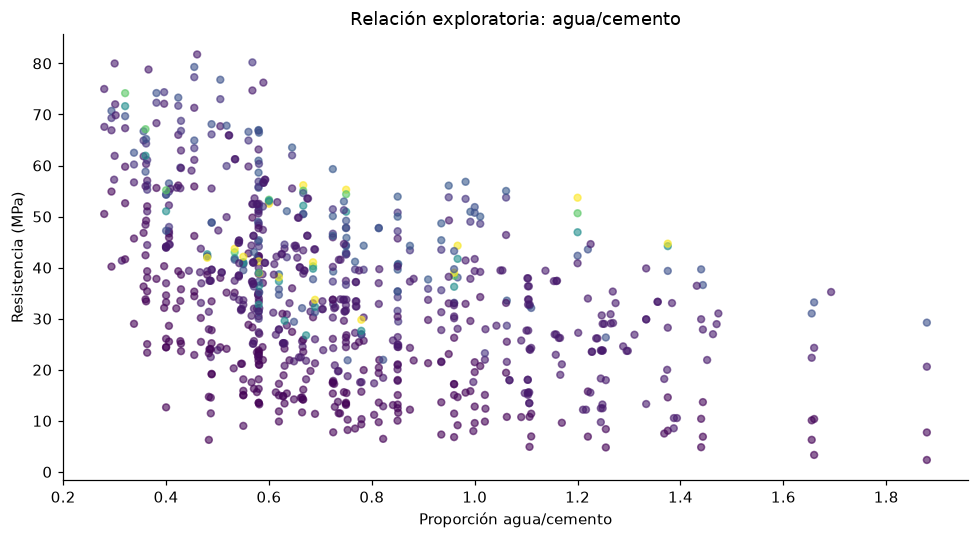

Correlación agua/cemento con resistencia: -0.466
Mayor correlación absoluta individual: cemento


In [8]:
eda = train.assign(rango_edad=pd.cut(train.edad, [0,7,28,90,366],
                    labels=['1-7 días','8-28 días','29-90 días','91-365 días']))
display(eda.groupby('rango_edad', observed=True).resistencia.agg(['count','mean','median']).round(2))
fig, ax = plt.subplots()
ax.scatter(train.agua/train.cemento, y_train, c=train.edad, cmap='viridis', alpha=.6, s=20)
ax.set(xlabel='Proporción agua/cemento', ylabel='Resistencia (MPa)', title='Relación exploratoria: agua/cemento')
plt.tight_layout(); plt.savefig(OUT/'04_agua_cemento.png', bbox_inches='tight'); plt.show()
print('Correlación agua/cemento con resistencia:', round((train.agua/train.cemento).corr(y_train),3))
print('Mayor correlación absoluta individual:', corr.resistencia.drop('resistencia').abs().idxmax())

**Cómo influye el EDA:** las entradas tienen escalas diferentes, pero elegimos árboles, que no requieren estandarización. Las relaciones presentan dispersión: no es razonable explicar toda la resistencia mediante un solo ingrediente. Comparamos un árbol con un conjunto de árboles para capturar interacciones. No afirmamos que cambiar un ingrediente cause una mejora: las recetas pueden cambiar en varios componentes simultáneamente.

**Hallazgos de esta ejecución:** la mediana de resistencia de entrenamiento es 33,78 MPa y la edad más frecuente es 28 días. La cobertura desigual por edad motiva revisar también el error por rangos de edad. El cemento tiene la mayor correlación absoluta individual con la resistencia. La razón agua/cemento presenta una correlación de -0,466: orienta una hipótesis sobre la composición, pero no demuestra causalidad ni se incorpora como una novena entrada.

## 5. Alternativas e hiperparámetros
- **Referencia:** predecir siempre la media del entrenamiento. Sirve para comprobar si aprender aporta valor.
- **Árbol de decisión:** preguntas sucesivas como “¿la edad es menor que cierto valor?”. Fácil de explicar, pero puede memorizar.
- **Random Forest:** promedia muchos árboles entrenados con variaciones en sus muestras. Busca reducir la variabilidad de un árbol individual.

Usamos cinco particiones por grupos. Seleccionamos el menor **MAE medio de validación**, nunca el resultado de prueba. Probamos profundidades 4, 8 y sin límite, y hojas mínimas de 2 o 5 registros. En el bosque fijamos 150 árboles como presupuesto de cómputo; no afirmamos que sea el número óptimo.

In [9]:
cv = GroupKFold(n_splits=5)
for a,b in cv.split(X_train, y_train, g_train):
    assert set(g_train.iloc[a]).isdisjoint(set(g_train.iloc[b]))

referencia = DummyRegressor(strategy='mean')
scores_base = -cross_val_score(referencia, X_train, y_train, groups=g_train,
                              cv=cv, scoring='neg_mean_absolute_error')
opciones = {
    'Árbol': DecisionTreeRegressor(random_state=SEED),
    'Random Forest': RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=1)
}
rejilla = {'max_depth':[4,8,None], 'min_samples_leaf':[2,5]}
busquedas = {}
filas = [{'modelo':'Media (referencia)', 'MAE_CV':scores_base.mean(),
          'desv_CV':scores_base.std(), 'parametros':'Media del entrenamiento'}]
for nombre, estimador in opciones.items():
    busqueda = GridSearchCV(estimador, rejilla, cv=cv, scoring='neg_mean_absolute_error', n_jobs=1)
    busqueda.fit(X_train, y_train, groups=g_train)
    busquedas[nombre] = busqueda
    filas.append({'modelo':nombre, 'MAE_CV':-busqueda.best_score_,
                  'desv_CV':busqueda.cv_results_['std_test_score'][busqueda.best_index_],
                  'parametros':str(busqueda.best_params_)})
    pd.DataFrame(busqueda.cv_results_).to_csv(OUT/('busqueda_'+nombre.replace(' ','_')+'.csv'), index=False)
comparacion = pd.DataFrame(filas).sort_values('MAE_CV').reset_index(drop=True)
display(comparacion)
comparacion.to_csv(OUT/'comparacion_cv.csv', index=False)
ganador = comparacion.iloc[0]['modelo']
assert ganador in busquedas, 'Si la referencia gana, replantear el modelo antes de desplegar.'
modelo = busquedas[ganador].best_estimator_
print('Seleccionado por validación:', ganador, modelo.get_params())

,modelo,MAE_CV,desv_CV,parametros
0,Random Forest,4.701950,0.452513,"{'max_depth': None, 'min_samples_leaf': 2}"
1,Árbol,5.973283,0.431159,"{'max_depth': None, 'min_samples_leaf': 2}"
2,Media (referencia),13.217160,0.706688,Media del entrenamiento


Seleccionado por validación: Random Forest {'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 2, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 150, 'n_jobs': 1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


**Resultado de selección:** Random Forest obtuvo MAE de validación de 4,702 MPa (desviación 0,453), frente a 5,973 MPa del árbol y 13,217 MPa de la referencia. Se seleccionó profundidad sin límite y mínimo de dos muestras por hoja. En este bosque se usa `max_features=1.0`: cada división considera todas las variables; la diversidad proviene principalmente de las muestras bootstrap.

## 6. Evaluación final en recetas reservadas
Ahora usamos la prueba una sola vez para reportar resultados. No volveremos a modificar hiperparámetros a partir de estos resultados.

- **MAE:** error absoluto medio, en MPa. Es la métrica principal porque se interpreta en las mismas unidades del laboratorio.
- **RMSE:** también en MPa; penaliza más los errores grandes.
- **R²:** compara el error cuadrático con la variación de las respuestas de prueba. No es un porcentaje de aciertos, puede ser negativo y no demuestra seguridad estructural.

Comparamos entrenamiento, validación y prueba para reconocer sobreajuste. Una separación correcta reduce fugas, pero no garantiza ausencia absoluta de sesgos.

,evaluacion,MAE,RMSE,R2
0,Modelo: entrenamiento,1.715,2.605,0.974
1,Modelo: prueba,4.364,5.667,0.877
2,Referencia: prueba,12.921,16.158,-0.000


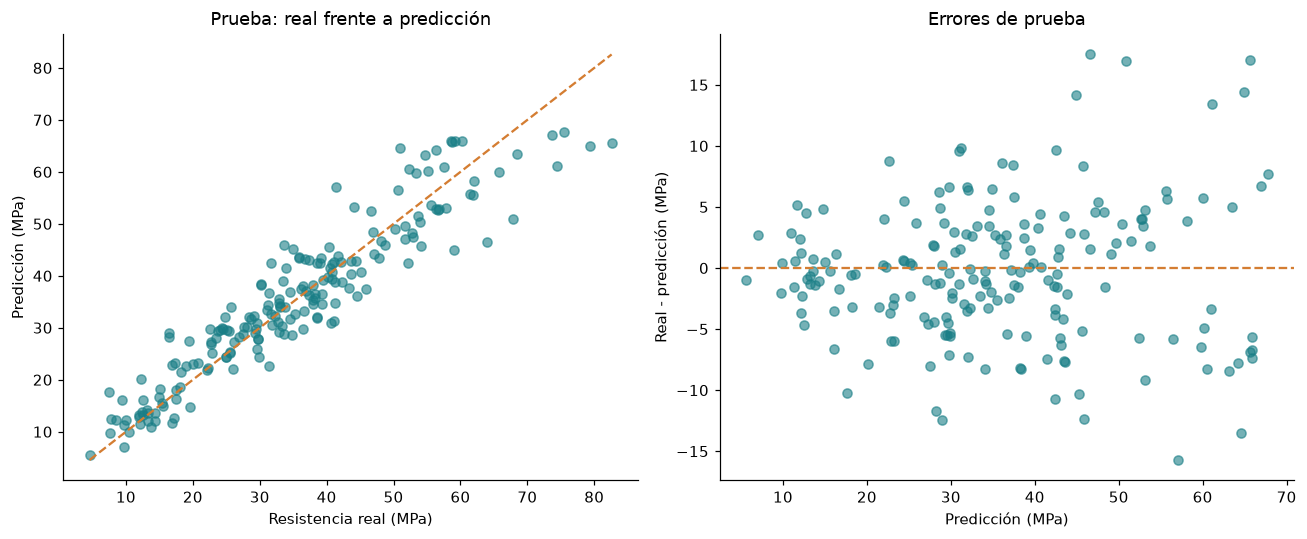

,cemento,escoria,ceniza,agua,superplastificante,agregado_grueso,agregado_fino,edad,real,prediccion,error_absoluto
358,505.0,0.0,60.0,195.0,0.00,1030.0,630.0,28,64.02,46.53,17.49
158,389.9,189.0,0.0,145.9,22.00,944.7,755.8,91,82.60,65.60,17.00
376,250.0,180.0,95.0,159.0,9.45,860.0,800.0,28,67.87,50.92,16.94
360,516.0,0.0,0.0,162.0,8.20,801.0,802.0,28,41.37,57.09,15.72
141,389.9,189.0,0.0,145.9,22.00,944.7,755.8,56,79.40,64.97,14.43


,count,mean
rango,,
"(0, 7]",41,3.96
"(7, 28]",98,4.51
"(28, 90]",28,4.69
"(90, 366]",28,4.10


In [10]:
def metricas(real, pred):
    return {'MAE':float(mean_absolute_error(real,pred)),
            'RMSE':float(np.sqrt(mean_squared_error(real,pred))),
            'R2':float(r2_score(real,pred))}
pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)
referencia.fit(X_train,y_train)
resultados = pd.DataFrame([
    {'evaluacion':'Modelo: entrenamiento', **metricas(y_train,pred_train)},
    {'evaluacion':'Modelo: prueba', **metricas(y_test,pred_test)},
    {'evaluacion':'Referencia: prueba', **metricas(y_test,referencia.predict(X_test))}
])
display(resultados.round(3))
resultados.to_csv(OUT/'metricas.csv', index=False)
errores = X_test.copy()
errores['real'] = y_test
errores['prediccion'] = pred_test
errores['error_absoluto'] = abs(y_test-pred_test)
errores.to_csv(OUT/'predicciones_prueba.csv', index=False)
fig, axes = plt.subplots(1,2,figsize=(12,5))
axes[0].scatter(y_test,pred_test,alpha=.6,color='#197e86')
lim = [min(y_test.min(),pred_test.min()),max(y_test.max(),pred_test.max())]
axes[0].plot(lim,lim,'--',color='#d47d32')
axes[0].set(xlabel='Resistencia real (MPa)',ylabel='Predicción (MPa)',title='Prueba: real frente a predicción')
axes[1].scatter(pred_test,y_test-pred_test,alpha=.6,color='#197e86')
axes[1].axhline(0,color='#d47d32',linestyle='--')
axes[1].set(xlabel='Predicción (MPa)',ylabel='Real - predicción (MPa)',title='Errores de prueba')
plt.tight_layout(); plt.savefig(OUT/'05_evaluacion.png',bbox_inches='tight'); plt.show()
display(errores.nlargest(5,'error_absoluto').round(2))
por_edad = errores.assign(rango=pd.cut(errores.edad,[0,7,28,90,366]))
display(por_edad.groupby('rango',observed=True).error_absoluto.agg(['count','mean']).round(2))

**Interpretación de la prueba:** MAE = 4,364 MPa, RMSE = 5,667 MPa y R² = 0,877. La referencia tiene MAE = 12,921 MPa: el bosque reduce este error aproximadamente un 66,2 %. El MAE de entrenamiento (1,715) es menor que el de prueba, por lo que existe una brecha de generalización. La prueba es coherente con la validación (4,702); no afirmamos ausencia total de sobreajuste. El gráfico real/predicho muestra subestimaciones en parte de las resistencias altas y los errores más grandes deben reconocerse como limitación.

## 7. Explicación del modelo
Visualizamos los primeros niveles del árbol comparado. Si el bosque gana, este dibujo explica el funcionamiento de un árbol, **no todas las decisiones del bosque**. La importancia por reducción de impureza es descriptiva, puede favorecer variables con muchos valores y no demuestra causalidad.

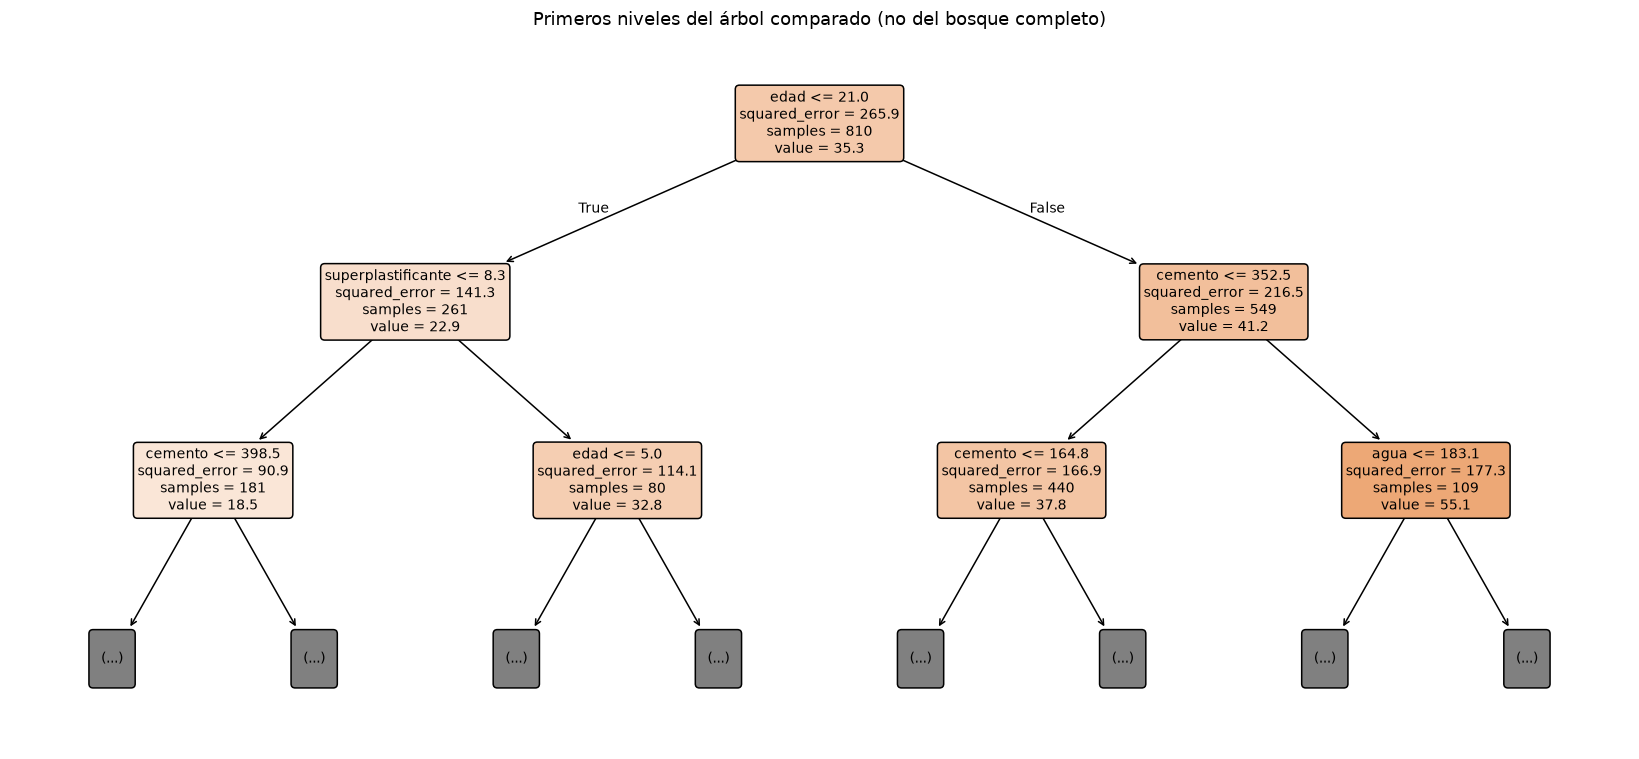

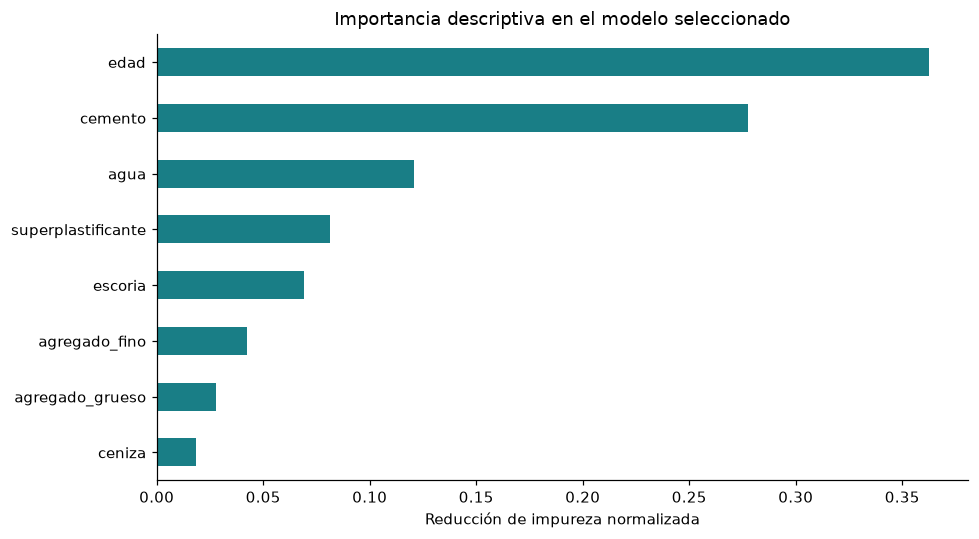

In [11]:
fig, ax = plt.subplots(figsize=(15,7))
plot_tree(busquedas['Árbol'].best_estimator_, feature_names=features, max_depth=2,
          filled=True, rounded=True, precision=1, fontsize=9, ax=ax)
ax.set_title('Primeros niveles del árbol comparado (no del bosque completo)')
plt.tight_layout(); plt.savefig(OUT/'06_arbol.png',bbox_inches='tight'); plt.show()
importancias = pd.Series(modelo.feature_importances_,index=features).sort_values()
importancias.plot.barh(color='#197e86',title='Importancia descriptiva en el modelo seleccionado')
plt.xlabel('Reducción de impureza normalizada'); plt.tight_layout()
plt.savefig(OUT/'07_importancias.png',bbox_inches='tight'); plt.show()

## 8. Guardar y conectar con la interfaz
Conservamos el modelo entrenado **solo con entrenamiento**: es exactamente el que evaluamos. Además de `joblib`, exportamos los umbrales y hojas de los árboles a JSON. La aplicación web recorre esos mismos árboles y promedia sus resultados; no usa una fórmula aproximada ni respuestas prefijadas.

Esto permite alojar la aplicación como página estática, sin un servidor Python. La entrada se convierte a float32 para coincidir con scikit-learn. El MAE mostrado es un error histórico promedio, no un intervalo de confianza individual.

In [12]:
joblib.dump(modelo,'models/modelo.joblib')
def exportar_arbol(est):
    t = est.tree_
    return {'left':t.children_left.tolist(), 'right':t.children_right.tolist(),
            'feature':t.feature.tolist(), 'threshold':t.threshold.tolist(),
            'value':t.value[:,0,0].tolist()}
arboles = modelo.estimators_ if hasattr(modelo,'estimators_') else [modelo]
resumen = {
    'modelo':ganador, 'seed':SEED, 'sklearn_version':sklearn.__version__,
    'filas_originales':len(original), 'duplicados':duplicados, 'filas_limpias':len(datos),
    'train_filas':len(X_train), 'test_filas':len(X_test),
    'train_grupos':int(g_train.nunique()), 'test_grupos':int(g_test.nunique()),
    'hiperparametros':busquedas[ganador].best_params_,
    'mae_cv':float(comparacion.iloc[0].MAE_CV),
    'std_cv':float(comparacion.iloc[0].desv_CV),
    'train':metricas(y_train,pred_train), 'test':metricas(y_test,pred_test),
    'baseline_test':metricas(y_test,referencia.predict(X_test)),
    'fuente':'https://doi.org/10.24432/C5PK67',
    'sha256_excel':hashlib.sha256(ruta.read_bytes()).hexdigest()
}
limites = {c:{'min':float(X_train[c].min()),'max':float(X_train[c].max())} for c in features}
ejemplos = []
for nombre,pos in [('Ejemplo A',0),('Ejemplo B',len(X_train)//2),('Ejemplo C',len(X_train)-1)]:
    fila = X_train.iloc[pos]
    ejemplos.append({'nombre':nombre,'valores':[float(fila[c]) for c in features]})
exportado = {'features':features,'trees':[exportar_arbol(a) for a in arboles],
             'limits':limites,'examples':ejemplos,'metrics':resumen}
Path('docs/modelo.json').write_text(json.dumps(exportado,ensure_ascii=False),encoding='utf-8')
(OUT/'resumen.json').write_text(json.dumps(resumen,indent=2,ensure_ascii=False),encoding='utf-8')
# Referencia para verificar que JavaScript produce las mismas predicciones.
(OUT/'verificacion_web.json').write_text(json.dumps({'X':X.to_numpy().tolist(),
    'pred':modelo.predict(X).tolist()}),encoding='utf-8')
display(pd.DataFrame([resumen['test']]).round(3))
print('Modelo e indicadores guardados. No se reentrenó con prueba.')

,MAE,RMSE,R2
0,4.364,5.667,0.877


Modelo e indicadores guardados. No se reentrenó con prueba.


## 9. Reajuste en producción (estrategia propuesta)
1. Guardar versión, fecha, entradas y predicción; cuando exista un ensayo real, vincular su resultado. No usar predicciones como etiquetas reales.
2. Revisar mensualmente valores fuera de los rangos de entrenamiento y errores cuando haya al menos 50 ensayos nuevos. Sin respuestas reales solo podemos detectar cambios de entradas, no medir desempeño.
3. Investigar si más del 10 % de las entradas sale de los rangos, o si el MAE de los últimos 50 ensayos supera 1,25 veces el MAE de referencia de prueba durante dos revisiones. Son umbrales iniciales propuestos, no límites validados por una norma.
4. Revisar trimestralmente si hay suficientes ensayos nuevos. Reentrenar si se confirma deterioro o cambian materiales/procesos, conservando los datos y el modelo anteriores.
5. Separar recetas y reservar datos recientes para evaluar una nueva versión. Comparar contra el modelo vigente con MAE y RMSE, incluyendo segmentos por edad. Aprobar solo si hay mejora y no se empeoran segmentos relevantes.
6. Actualizar JSON y modelo de forma conjunta, repetir la prueba Python/JavaScript, registrar versión y conservar la anterior para volver atrás si falla.

No implementamos un sistema de monitoreo real porque aún no hay ensayos de producción. La interfaz no recoge datos automáticamente.

## 10. Límites y conclusiones
- El conjunto es histórico y tiene un origen específico. Hacen falta datos locales para validar uso en otro laboratorio.
- Separar recetas reduce una fuga evidente; no permite asegurar independencia por lote porque ese identificador no está disponible.
- Los ingredientes deben usar las unidades originales. Estar dentro de rangos individuales no garantiza que una combinación sea una receta plausible.
- No confundimos correlación/importancia con causalidad ni MAE con un margen garantizado.
- Una diferencia entre error de entrenamiento y prueba se informa; no se oculta afirmando que no hay sobreajuste.
- La interfaz apoya estimaciones preliminares y no sustituye ensayos de resistencia.

**Conclusión:** el bosque seleccionado mejora la referencia en recetas reservadas. La interfaz utiliza exactamente el modelo evaluado y permite consultar estimaciones preliminares con límites de entrada explícitos.